# Usertest-Auswertung

## Setup

In [31]:
# %pip install pandas matplotlib seaborn scipy jupyter

In [32]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("data")
FIGURE_DIR = Path("figures_data")
OUTPUT_DIR = Path("outputs_data")
FIGURE_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

## Daten einlesen

In [33]:
def load_json_tolerant(path: Path):
    """Laedt JSON. Falls nur ein trailing comma vor ] oder } stoert, wird es toleriert."""
    text = path.read_text(encoding="utf-8")
    try:
        return json.loads(text), "strict"
    except json.JSONDecodeError:
        cleaned = re.sub(r",\s*([}\]])", r"\1", text)
        return json.loads(cleaned), "recovered_trailing_comma"


def parse_participant(path: Path):
    match = re.match(r"(?P<code>\d+(?:-\d+)?)-(?P<name>.+)", path.stem)
    if not match:
        return path.stem, path.stem
    return match.group("code"), match.group("name")


# Einheitliche Anzeige der Bedingungen in Tabellen und Diagrammen.
PRESET_LABELS = {
    "grounding-shadows-only": "L01: Grounding Shadows",
    "baseline-dominant": "L03: Baseline",
    "multilight-color-true-geometry": "L05: Multi-Light mit Geometrie",
    "directional-geometry-no-shadows": "L06: Multi-Light + Grounding Shadows",
    "multilight-color-true-geometry-key-fill": "L07: Multi-Light Single Shadow",
    "multilight-single-hard-shadow": "L08: Multi-Light Single Hard Shadow",
    "multilight-live-updates": "L09: Multi-Light Live Updates",
}

rows = []
file_status = []

for path in sorted(DATA_DIR.glob("*.json")):
    code, name = parse_participant(path)
    data, parse_status = load_json_tolerant(path)
    file_status.append({"file": path.name, "parse_status": parse_status})

    for response_index, response in enumerate(data.get("responses", [])):
        if response.get("responseKind") != "questionnaire":
            continue

        for answer in response.get("answers", []):
            rows.append({
                "file": path.name,
                "participant_code": code,
                "response_index": response_index,
                "preset": PRESET_LABELS.get(
                    response.get("presetID"), response.get("presetTitle")
                ),
                "recorded_at": response.get("recordedAt"),
                "question_index": answer.get("questionIndex"),
                "question": answer.get("question"),
                "rating": answer.get("rating"),
            })

df = pd.DataFrame(rows)
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["recorded_at"] = pd.to_datetime(df["recorded_at"], errors="coerce")

# Frage 6 ist negativ formuliert: hoeherer Score soll immer positiver bedeuten. -> invertieren
df["score"] = df["rating"]
df.loc[df["question_index"] == 6, "score"] = 6 - df.loc[df["question_index"] == 6, "rating"]

file_status = pd.DataFrame(file_status)
display(file_status)
df.head()

,file,parse_status
0,01.json,strict
1,02.json,strict
2,04.json,strict
3,05.json,strict
4,06.json,strict
5,07.json,strict
6,08.json,strict
7,09.json,strict
8,10.json,strict
9,11.json,strict


,file,participant_code,response_index,preset,recorded_at,question_index,question,rating,score
0,01.json,01,0,L05: Multi-Light mit Geometrie,2026-07-22 13:32:54+00:00,1,Ich habe mich in der Umgebung wohl gefühlt.,5,5
1,01.json,01,0,L05: Multi-Light mit Geometrie,2026-07-22 13:32:54+00:00,2,Ich kam mit der Aufgabe gut zurecht.,4,4
2,01.json,01,0,L05: Multi-Light mit Geometrie,2026-07-22 13:32:54+00:00,3,"Die virtuellen Objekte verhielten sich so, wie...",4,4
3,01.json,01,0,L05: Multi-Light mit Geometrie,2026-07-22 13:32:54+00:00,4,Die virtuelle Szene fügte sich glaubwürdig in ...,4,4
4,01.json,01,0,L05: Multi-Light mit Geometrie,2026-07-22 13:32:54+00:00,5,Die Szene war visuell ansprechend.,4,4


## Bewertete Testposition bestimmen

Komplett leere Fragebogen-Eintraege werden fuer den Verlauf ausgeschlossen. Die Testposition wird nur ueber bewertete Frageboegen gezaehlt.

In [34]:
response_status = (
    df.groupby(["file", "response_index", "preset"], as_index=False)
    .agg(
        recorded_at=("recorded_at", "min"),
        answered_ratings=("rating", lambda s: s.notna().sum()),
        total_questions=("rating", "size"),
    )
    .sort_values(["file", "recorded_at", "response_index"])
)
response_status["has_rating"] = response_status["answered_ratings"] > 0
response_status["test_position"] = pd.NA

for file, indices in response_status[response_status["has_rating"]].groupby("file").groups.items():
    for position, index in enumerate(indices, start=1):
        response_status.loc[index, "test_position"] = position

df = df.merge(
    response_status[["file", "response_index", "test_position", "has_rating", "answered_ratings", "total_questions"]],
    on=["file", "response_index"],
    how="left",
)

display(response_status)
print("Bewertete Frageboegen:", int(response_status["has_rating"].sum()))
print("Komplett leere Frageboegen:", int((~response_status["has_rating"]).sum()))

,file,response_index,preset,recorded_at,answered_ratings,total_questions,has_rating,test_position
0,01.json,0,L05: Multi-Light mit Geometrie,2026-07-22 13:32:54+00:00,6,6,True,1
1,01.json,1,L08: Multi-Light Single Hard Shadow,2026-07-22 13:36:33+00:00,6,6,True,2
2,01.json,2,L03: Baseline,2026-07-22 13:39:44+00:00,6,6,True,3
3,01.json,3,L01: Grounding Shadows,2026-07-22 13:44:27+00:00,6,6,True,4
4,01.json,4,L06: Multi-Light + Grounding Shadows,2026-07-22 13:49:15+00:00,6,6,True,5
...,...,...,...,...,...,...,...,...
65,15.json,0,L03: Baseline,2026-07-28 12:19:13+00:00,6,6,True,1
66,15.json,1,L06: Multi-Light + Grounding Shadows,2026-07-28 12:22:06+00:00,6,6,True,2
67,15.json,2,L05: Multi-Light mit Geometrie,2026-07-28 12:25:09+00:00,6,6,True,3
68,15.json,3,L01: Grounding Shadows,2026-07-28 12:26:41+00:00,6,6,True,4


Bewertete Frageboegen: 70
Komplett leere Frageboegen: 0


## Verlauf pro Frage

Jeder Punkt ist der durchschnittliche Score aller vorhandenen Teilnehmerantworten an dieser Testposition. Die grauen Linien zeigen die einzelnen Personen im Hintergrund.

In [35]:
plot_df = df[df["has_rating"] & df["score"].notna()].copy()
plot_df["test_position"] = plot_df["test_position"].astype(int)
plot_df["question_label"] = "F" + plot_df["question_index"].astype(str)

question_means = (
    plot_df.groupby(["question_index", "question_label", "test_position"], as_index=False)
    .agg(
        mean_score=("score", "mean"),
        n=("score", "size"),
        sd=("score", "std"),
    )
)
question_means.to_csv(OUTPUT_DIR / "question_means_over_test_position.csv", index=False)
question_means

,question_index,question_label,test_position,mean_score,n,sd
0,1,F1,1,4.571429,14,0.646206
1,1,F1,2,4.642857,14,0.633324
2,1,F1,3,4.500000,14,0.650444
3,1,F1,4,4.285714,14,0.825420
4,1,F1,5,4.428571,14,0.755929
5,2,F2,1,4.285714,14,0.913874
6,2,F2,2,4.857143,14,0.534522
7,2,F2,3,4.714286,14,0.468807
8,2,F2,4,4.785714,14,0.578934
9,2,F2,5,4.857143,14,0.363137


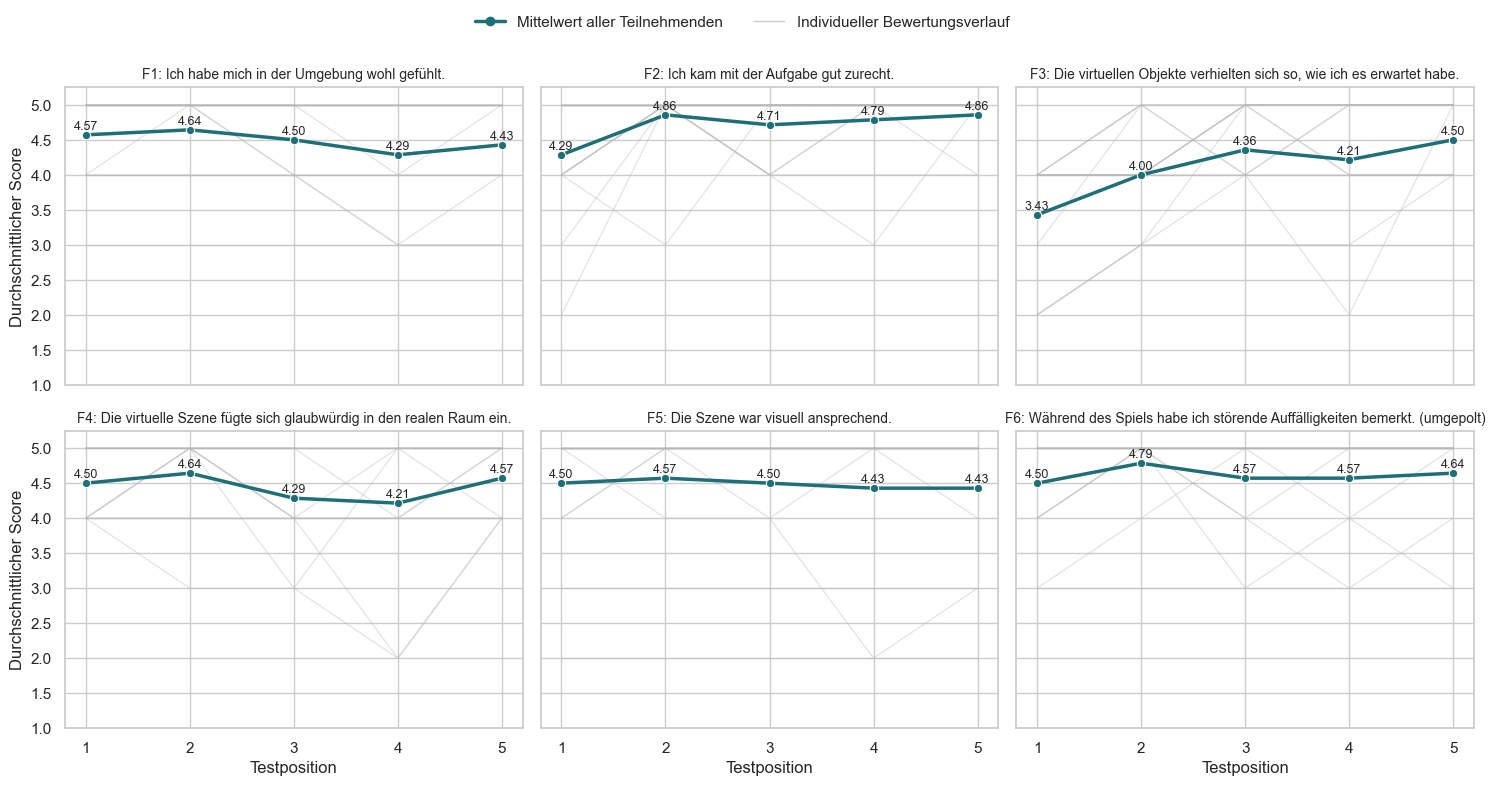

In [36]:
from matplotlib.lines import Line2D

questions = plot_df[["question_index", "question"]].drop_duplicates().sort_values("question_index")

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.flatten()
fig.legend(
    handles=[
        Line2D([0], [0], color="#1f6f78", marker="o", linewidth=2.5, label="Mittelwert aller Teilnehmenden"),
        Line2D([0], [0], color="#b6b6b6", linewidth=1, alpha=0.7, label="Individueller Bewertungsverlauf"),
    ],
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.99),
)

for ax, (_, question_row) in zip(axes, questions.iterrows()):
    question_index = question_row["question_index"]
    question_text = question_row["question"]
    subset = plot_df[plot_df["question_index"] == question_index]
    means = question_means[question_means["question_index"] == question_index]

    sns.lineplot(
        data=subset,
        x="test_position",
        y="score",
        units="file",
        estimator=None,
        color="#b6b6b6",
        alpha=0.35,
        linewidth=1,
        ax=ax,
    )
    sns.lineplot(
        data=means,
        x="test_position",
        y="mean_score",
        marker="o",
        color="#1f6f78",
        linewidth=2.5,
        ax=ax,
    )

    for _, row in means.iterrows():
        ax.text(row["test_position"], row["mean_score"] + 0.08, f'{row["mean_score"]:.2f}', ha="center", fontsize=9)

    score_note = " (umgepolt)" if question_index == 6 else ""
    ax.set_title(f"F{question_index}: {question_text}{score_note}", fontsize=10)
    ax.set_xlabel("Testposition")
    ax.set_ylabel("Durchschnittlicher Score")
    ax.set_ylim(1, 5.25)
    ax.set_xticks(sorted(plot_df["test_position"].unique()))

plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(FIGURE_DIR / "fragen_verlauf_ueber_testposition.png", dpi=300)
plt.show()

## Durchschnitt aus allen Fragen

Hier wird pro Person und bewerteter Bedingung ein Gesamtscore gebildet: der Durchschnitt aus den sechs Fragen. Frage 6 ist dabei bereits invertiert, damit hoeher immer positiver bedeutet.

In [37]:
overall_by_response = (
    plot_df.groupby(["file", "preset", "test_position"], as_index=False)
    .agg(
        overall_score=("score", "mean"),
        answered_questions=("score", "size"),
    )
)

overall_mean_by_position = (
    overall_by_response.groupby("test_position", as_index=False)
    .agg(
        mean_overall_score=("overall_score", "mean"),
        n=("overall_score", "size"),
        sd=("overall_score", "std"),
    )
)

overall_by_response.to_csv(OUTPUT_DIR / "overall_scores_by_person_condition.csv", index=False)
overall_mean_by_position.to_csv(OUTPUT_DIR / "overall_mean_over_test_position.csv", index=False)

display(overall_mean_by_position)
overall_by_response.head()

,test_position,mean_overall_score,n,sd
0,1,4.297619,14,0.382181
1,2,4.583333,14,0.374109
2,3,4.488095,14,0.425994
3,4,4.416667,14,0.591066
4,5,4.571429,14,0.456268


,file,preset,test_position,overall_score,answered_questions
0,01.json,L01: Grounding Shadows,4,3.500000,6
1,01.json,L03: Baseline,3,4.000000,6
2,01.json,L05: Multi-Light mit Geometrie,1,4.333333,6
3,01.json,L06: Multi-Light + Grounding Shadows,5,3.833333,6
4,01.json,L08: Multi-Light Single Hard Shadow,2,4.666667,6


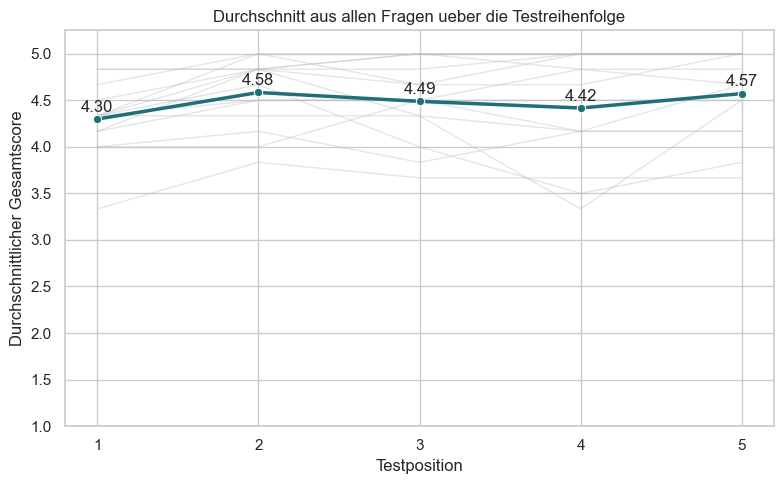

In [38]:
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=overall_by_response,
    x="test_position",
    y="overall_score",
    units="file",
    estimator=None,
    color="#b6b6b6",
    alpha=0.35,
    linewidth=1,
)
sns.lineplot(
    data=overall_mean_by_position,
    x="test_position",
    y="mean_overall_score",
    marker="o",
    color="#1f6f78",
    linewidth=2.5,
)

for _, row in overall_mean_by_position.iterrows():
    plt.text(row["test_position"], row["mean_overall_score"] + 0.08, f'{row["mean_overall_score"]:.2f}', ha="center")

plt.xlabel("Testposition")
plt.ylabel("Durchschnittlicher Gesamtscore")
plt.ylim(1, 5.25)
plt.xticks(sorted(overall_by_response["test_position"].unique()))
plt.title("Durchschnitt aus allen Fragen ueber die Testreihenfolge")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "gesamtverlauf_ueber_testposition.png", dpi=300)
plt.show()

## Likert-Verteilung pro Lichtbedingung

Diese Diagramme zeigen pro Frage, wie sich die Roh-Ratings 1 bis 5 auf die Lichtbedingungen verteilen. Jede Lichtbedingung wird innerhalb der jeweiligen Frage auf 100 Prozent normiert. Dadurch sind Bedingungen mit unterschiedlich vielen vorhandenen Antworten vergleichbar.

Hier wird bewusst `rating` verwendet, nicht der invertierte `score`. Frage 6 bleibt also in ihrer Originalform sichtbar.

In [39]:
likert_df = df[df["has_rating"] & df["rating"].notna()].copy()
likert_df["rating"] = likert_df["rating"].astype(int)

likert_counts = (
    likert_df.groupby(["question_index", "question", "preset", "rating"], as_index=False)
    .agg(n=("rating", "size"))
)
likert_counts["total_for_question_preset"] = likert_counts.groupby(["question_index", "preset"])["n"].transform("sum")
likert_counts["percent"] = likert_counts["n"] / likert_counts["total_for_question_preset"] * 100

likert_counts.to_csv(OUTPUT_DIR / "likert_counts_percent_by_question_preset.csv", index=False)
likert_counts.head()

,question_index,question,preset,rating,n,total_for_question_preset,percent
0,1,Ich habe mich in der Umgebung wohl gefühlt.,L01: Grounding Shadows,3,2,14,14.285714
1,1,Ich habe mich in der Umgebung wohl gefühlt.,L01: Grounding Shadows,4,5,14,35.714286
2,1,Ich habe mich in der Umgebung wohl gefühlt.,L01: Grounding Shadows,5,7,14,50.000000
3,1,Ich habe mich in der Umgebung wohl gefühlt.,L03: Baseline,3,2,14,14.285714
4,1,Ich habe mich in der Umgebung wohl gefühlt.,L03: Baseline,4,5,14,35.714286


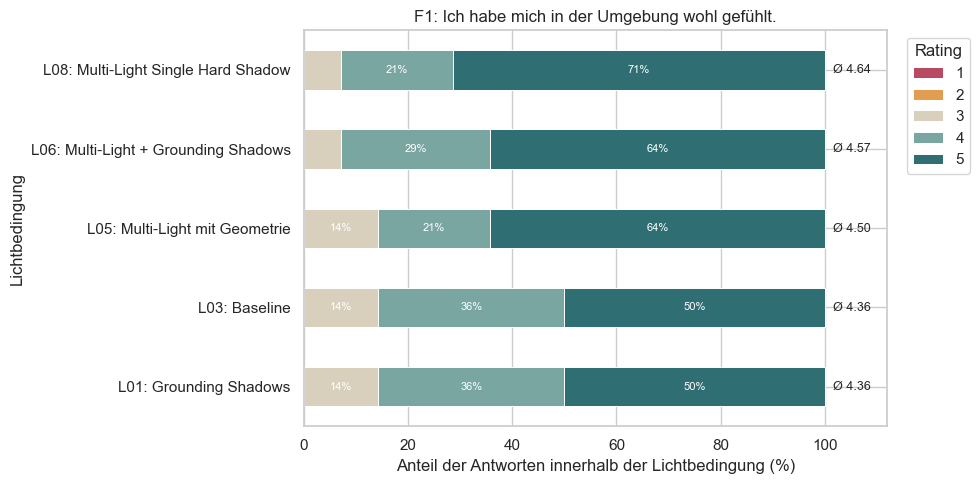

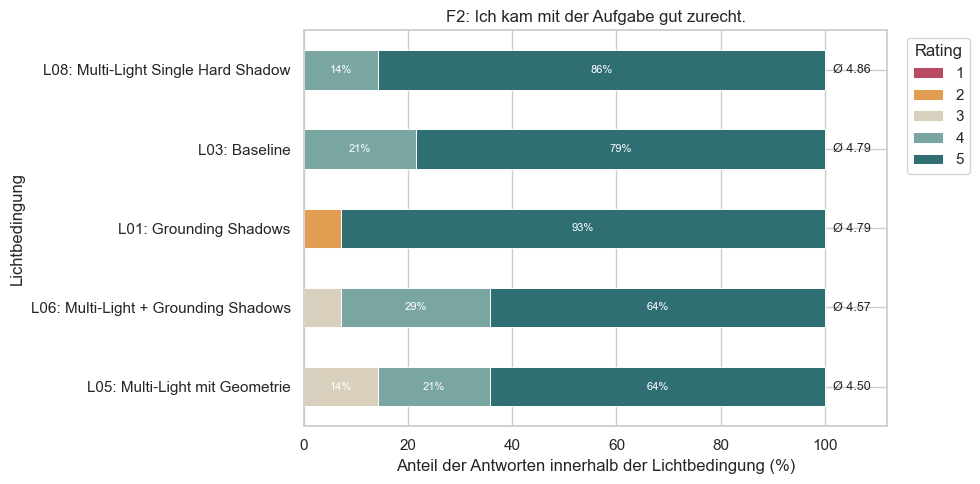

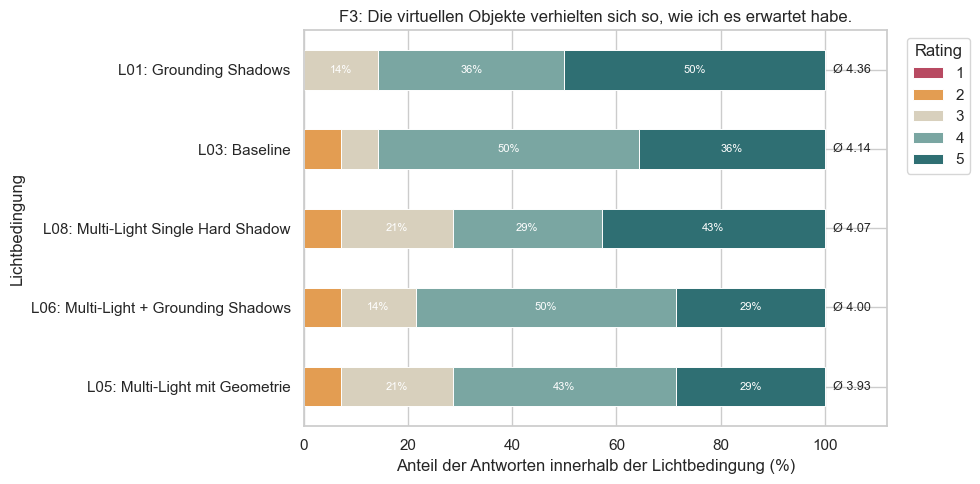

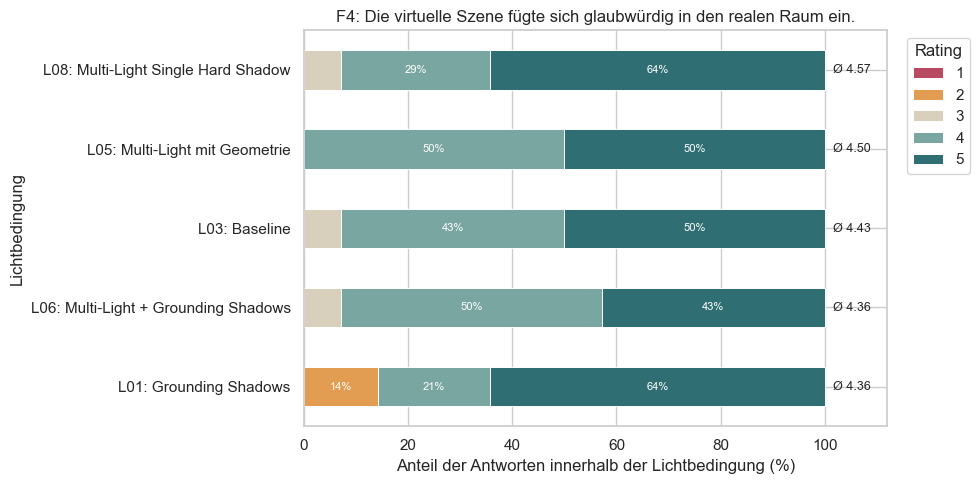

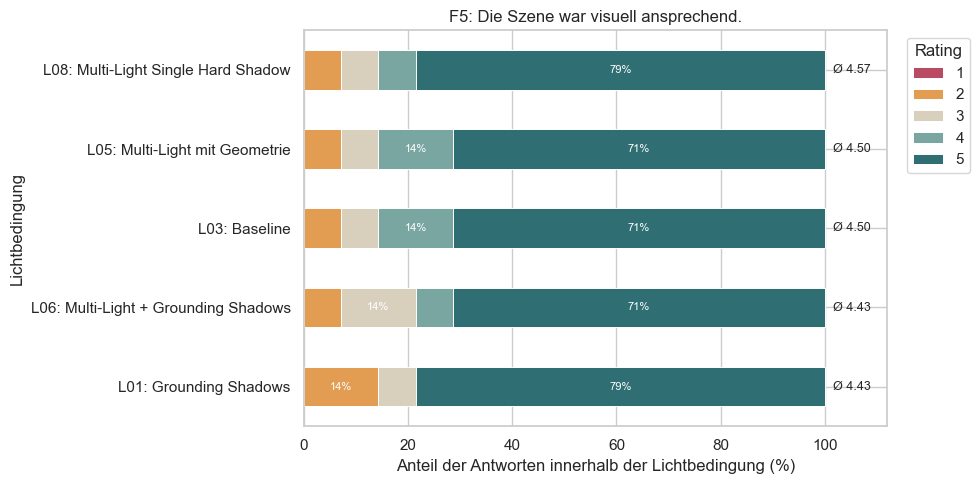

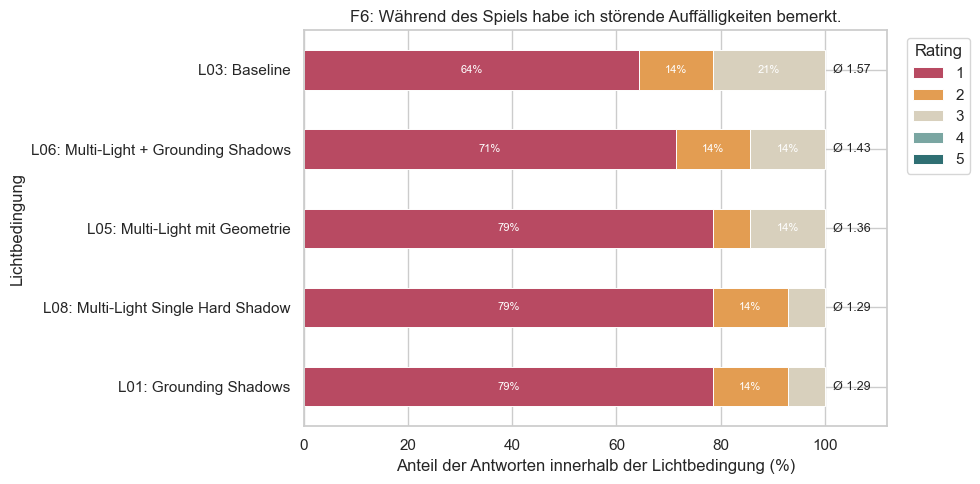

In [40]:
LIKERT_COLORS = {
    1: "#b84a62",
    2: "#e39d52",
    3: "#d8d0bd",
    4: "#7aa6a2",
    5: "#2f6f73",
}

preset_order = sorted(likert_df["preset"].dropna().unique())

def plot_likert_distribution(question_index):
    question_text = (
        likert_df.loc[likert_df["question_index"] == question_index, "question"]
        .dropna()
        .iloc[0]
    )
    subset = likert_df[likert_df["question_index"] == question_index].copy()
    counts = pd.crosstab(subset["preset"], subset["rating"])
    counts = counts.reindex(index=preset_order, columns=[1, 2, 3, 4, 5], fill_value=0)
    percents = counts.div(counts.sum(axis=1), axis=0) * 100
    percents = percents.fillna(0)
    mean_rating_by_preset = subset.groupby("preset")["rating"].mean().reindex(preset_order)
    question_preset_order = mean_rating_by_preset.sort_values(ascending=True).index
    percents = percents.loc[question_preset_order]
    mean_rating_by_preset = mean_rating_by_preset.loc[question_preset_order]

    ax = percents.plot(
        kind="barh",
        stacked=True,
        figsize=(10, 5),
        color=[LIKERT_COLORS[rating] for rating in [1, 2, 3, 4, 5]],
        edgecolor="white",
        linewidth=0.7,
    )

    for container in ax.containers:
        labels = []
        for value in container.datavalues:
            labels.append(f"{value:.0f}%" if value >= 9 else "")
        ax.bar_label(container, labels=labels, label_type="center", fontsize=8, color="white")

    for y_position, preset in enumerate(percents.index):
        mean_rating = mean_rating_by_preset.loc[preset]
        if pd.notna(mean_rating):
            ax.text(101.5, y_position, f"Ø {mean_rating:.2f}", va="center", fontsize=9)

    ax.set_xlim(0, 112)
    ax.set_xlabel("Anteil der Antworten innerhalb der Lichtbedingung (%)")
    ax.set_ylabel("Lichtbedingung")
    ax.set_title(f"F{question_index}: {question_text}")
    ax.legend(title="Rating", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"likert_prozent_frage_{question_index}.png", dpi=300)
    plt.show()


for question_index in sorted(likert_df["question_index"].dropna().unique()):
    plot_likert_distribution(int(question_index))

## Durchschnittsscore pro Lichtbedingung

Hier werden zwei Scores pro Lichtbedingung berechnet:

- `score_all_questions`: Durchschnitt aus allen sechs Fragen.
- `score_without_f2_f3`: Durchschnitt ohne Frage 2 und Frage 3, weil diese staerker durch die zeitliche Reihenfolge beeinflusst sein koennen.

Frage 6 ist weiterhin invertiert, damit ein hoeherer Score immer positiver bedeutet.

In [41]:
rated_scores = df[df["has_rating"] & df["score"].notna()].copy()

score_all_by_person_condition = (
    rated_scores.groupby(["file", "preset"], as_index=False)
    .agg(
        score_all_questions=("score", "mean"),
        answered_questions_all=("score", "size"),
    )
)

score_without_f2_f3_by_person_condition = (
    rated_scores[~rated_scores["question_index"].isin([2, 3])]
    .groupby(["file", "preset"], as_index=False)
    .agg(
        score_without_f2_f3=("score", "mean"),
        answered_questions_without_f2_f3=("score", "size"),
    )
)

score_by_person_condition = score_all_by_person_condition.merge(
    score_without_f2_f3_by_person_condition,
    on=["file", "preset"],
    how="outer",
)
score_by_person_condition.to_csv(OUTPUT_DIR / "scores_by_person_condition_all_vs_without_f2_f3.csv", index=False)
score_by_person_condition.head()

,file,preset,score_all_questions,answered_questions_all,score_without_f2_f3,answered_questions_without_f2_f3
0,01.json,L01: Grounding Shadows,3.500000,6,2.75,4
1,01.json,L03: Baseline,4.000000,6,3.50,4
2,01.json,L05: Multi-Light mit Geometrie,4.333333,6,4.50,4
3,01.json,L06: Multi-Light + Grounding Shadows,3.833333,6,3.50,4
4,01.json,L08: Multi-Light Single Hard Shadow,4.666667,6,4.50,4


In [42]:
score_summary_by_preset = (
    score_by_person_condition.groupby("preset", as_index=False)
    .agg(
        n_all=("score_all_questions", "count"),
        mean_all_questions=("score_all_questions", "mean"),
        median_all_questions=("score_all_questions", "median"),
        sd_all_questions=("score_all_questions", "std"),
        n_without_f2_f3=("score_without_f2_f3", "count"),
        mean_without_f2_f3=("score_without_f2_f3", "mean"),
        median_without_f2_f3=("score_without_f2_f3", "median"),
        sd_without_f2_f3=("score_without_f2_f3", "std"),
    )
)
score_summary_by_preset["difference_without_minus_all"] = (
    score_summary_by_preset["mean_without_f2_f3"] - score_summary_by_preset["mean_all_questions"]
)
score_summary_by_preset = score_summary_by_preset.sort_values("mean_without_f2_f3", ascending=False)
score_summary_by_preset.to_csv(OUTPUT_DIR / "score_summary_by_preset_all_vs_without_f2_f3.csv", index=False)
score_summary_by_preset

,preset,n_all,mean_all_questions,median_all_questions,sd_all_questions,n_without_f2_f3,mean_without_f2_f3,median_without_f2_f3,sd_without_f2_f3,difference_without_minus_all
4,L08: Multi-Light Single Hard Shadow,14,4.571429,4.666667,0.417124,14,4.625000,4.625,0.435780,0.053571
2,L05: Multi-Light mit Geometrie,14,4.428571,4.500000,0.505163,14,4.535714,4.625,0.498624,0.107143
3,L06: Multi-Light + Grounding Shadows,14,4.416667,4.500000,0.417307,14,4.482143,4.750,0.575663,0.065476
0,L01: Grounding Shadows,14,4.500000,4.750000,0.543021,14,4.464286,4.625,0.656749,-0.035714
1,L03: Baseline,14,4.440476,4.416667,0.411414,14,4.428571,4.500,0.513553,-0.011905


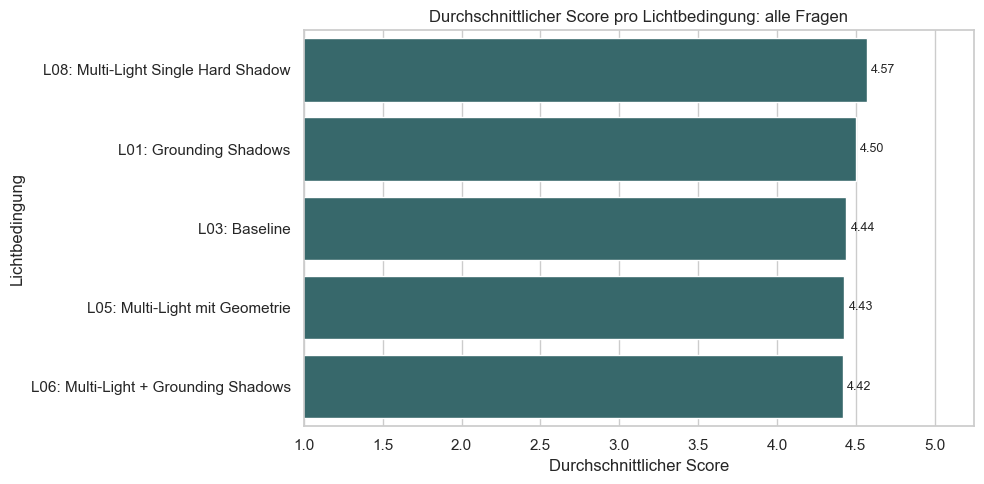

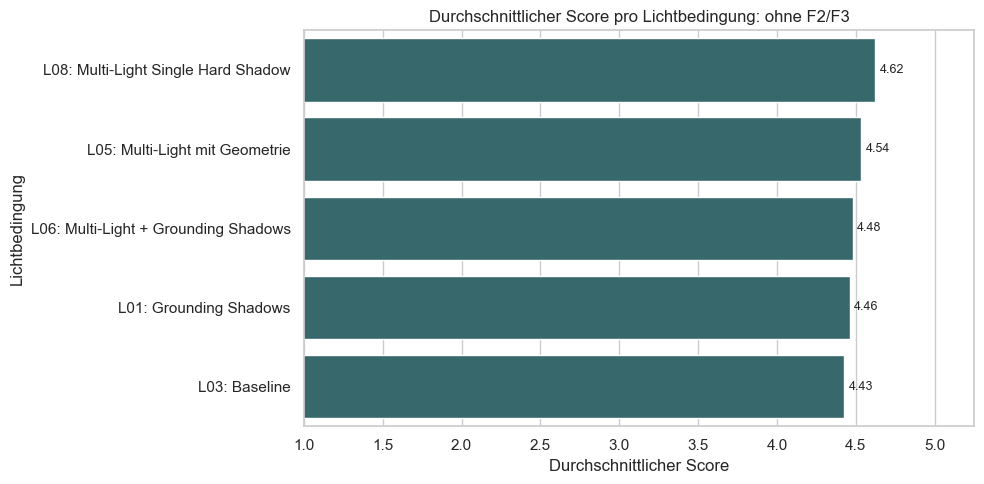

In [43]:
def plot_mean_score_by_preset(summary_df, mean_col, n_col, title, filename):
    plot_data = summary_df[["preset", mean_col, n_col]].copy()
    plot_data = plot_data.sort_values(mean_col, ascending=False)

    plt.figure(figsize=(10, 5))
    ax = sns.barplot(
        data=plot_data,
        y="preset",
        x=mean_col,
        color="#2f6f73",
    )
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

    plt.xlim(1, 5.25)
    plt.xlabel("Durchschnittlicher Score")
    plt.ylabel("Lichtbedingung")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=300)
    plt.show()


plot_mean_score_by_preset(
    score_summary_by_preset,
    mean_col="mean_all_questions",
    n_col="n_all",
    title="Durchschnittlicher Score pro Lichtbedingung: alle Fragen",
    filename="durchschnittsscore_pro_lichtbedingung_alle_fragen.png",
)

plot_mean_score_by_preset(
    score_summary_by_preset,
    mean_col="mean_without_f2_f3",
    n_col="n_without_f2_f3",
    title="Durchschnittlicher Score pro Lichtbedingung: ohne F2/F3",
    filename="durchschnittsscore_pro_lichtbedingung_ohne_f2_f3.png",
)

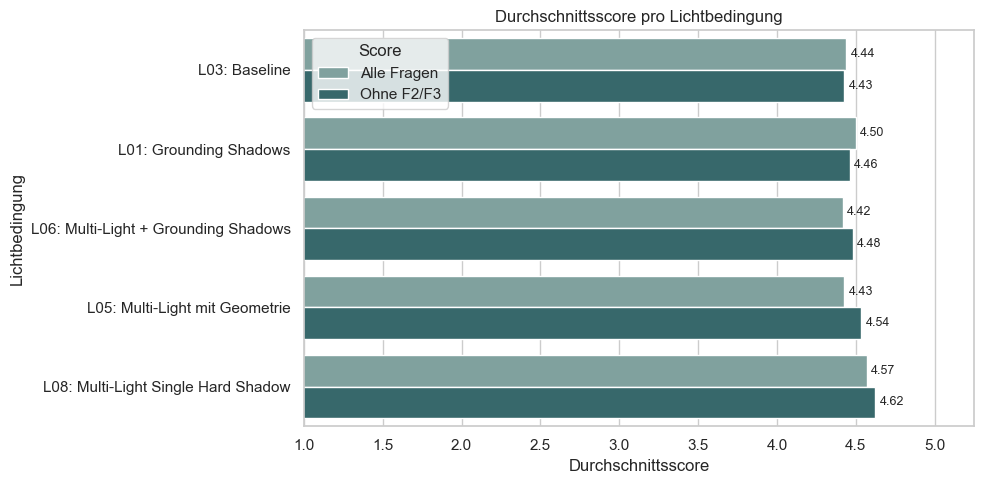

In [44]:
plot_scores = score_summary_by_preset.melt(
    id_vars="preset",
    value_vars=["mean_all_questions", "mean_without_f2_f3"],
    var_name="score_type",
    value_name="mean_score",
)
plot_scores["score_type"] = plot_scores["score_type"].map({
    "mean_all_questions": "Alle Fragen",
    "mean_without_f2_f3": "Ohne F2/F3",
})

preset_order_for_scores = score_summary_by_preset.sort_values("mean_without_f2_f3", ascending=True)["preset"]

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=plot_scores,
    y="preset",
    x="mean_score",
    hue="score_type",
    order=preset_order_for_scores,
    palette=["#7aa6a2", "#2f6f73"],
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.xlim(1, 5.25)
plt.xlabel("Durchschnittsscore")
plt.ylabel("Lichtbedingung")
plt.title("Durchschnittsscore pro Lichtbedingung")
plt.legend(title="Score")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "durchschnittsscore_pro_lichtbedingung_all_vs_ohne_f2_f3.png", dpi=300)
plt.show()

/var/folders/n5/rtq1wtz96898k139rmf2jxg00000gs/T/ipykernel_43805/2985201991.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.pointplot(
/var/folders/n5/rtq1wtz96898k139rmf2jxg00000gs/T/ipykernel_43805/2985201991.py:11: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(


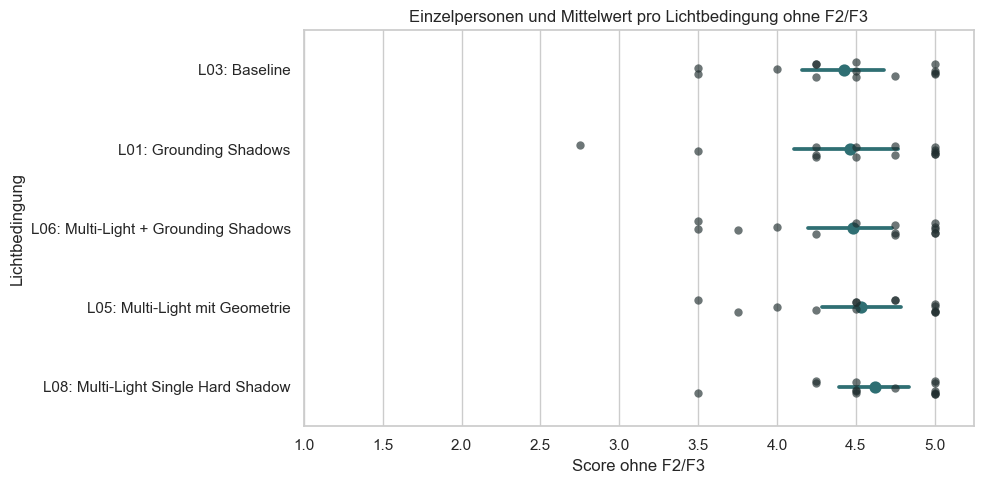

In [45]:
plt.figure(figsize=(10, 5))
sns.stripplot(
    data=score_by_person_condition,
    y="preset",
    x="score_without_f2_f3",
    order=preset_order_for_scores,
    color="#1f2d2e",
    size=6,
    alpha=0.65,
)
sns.pointplot(
    data=score_by_person_condition,
    y="preset",
    x="score_without_f2_f3",
    order=preset_order_for_scores,
    color="#2f6f73",
    join=False,
    ci=95,
)
plt.xlim(1, 5.25)
plt.xlabel("Score ohne F2/F3")
plt.ylabel("Lichtbedingung")
plt.title("Einzelpersonen und Mittelwert pro Lichtbedingung ohne F2/F3")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "score_ohne_f2_f3_personen_pro_lichtbedingung.png", dpi=300)
plt.show()